# Loss of Exclusivity: How Fast Do Brands Erode, and What Happens to Eliquis in 2028?

**Business question:** When a brand loses exclusivity, how fast does it lose
volume, and can an analog-based forecast be trusted? Then apply it to the
biggest upcoming case: Eliquis (apixaban), expected to face US generics from April 2028.

**Data:** Medicaid State Drug Utilization Data (SDUD), 2017 onward. For every
quarter it reports prescriptions, units and dollars Medicaid reimbursed for each
drug product, so brand and generic versions of the same molecule can be told apart.

**Method:**
1. Build quarterly brand vs. generic prescriptions for brands that already lost exclusivity (the **analogs**).
2. Align them on the quarter generics arrived and measure the **erosion curve**: the brand's share of its molecule's prescriptions in each quarter after entry.
3. **Back-test**: forecast the 2025 Brilinta and Entresto LOEs using only older analogs, and compare with what actually happened.
4. Apply the curves to Eliquis, taking account of a December 2025 change in how Medicaid buys it.

Terms: **LOE** (loss of exclusivity) is when patents and regulatory exclusivity
end and generics can launch. **Biosimilars** are the near-copies of biologic
drugs, the biologic equivalent of generics.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

HERE = Path.cwd() if Path.cwd().name.startswith("03-") else Path("03-loe-erosion-forecast")
sys.path.insert(0, str(HERE.parent))
from common import style  # noqa: E402

style.apply()
RAW, FIG, TAB = HERE / "data" / "raw", HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
SRC = "Medicaid State Drug Utilization Data (CMS), national totals"

import json
MOLECULES = json.loads((RAW / "sources.json").read_text())["molecules"]

frames = [pd.read_csv(f, dtype=str) for f in sorted(RAW.glob("sdud_*.csv.gz"))]
sd = pd.concat(frames, ignore_index=True)
for c in ["units_reimbursed", "number_of_prescriptions", "total_amount_reimbursed", "medicaid_amount_reimbursed"]:
    sd[c] = pd.to_numeric(sd[c], errors="coerce")
sd["year"] = sd["year"].astype(int)
sd["quarter"] = sd["quarter"].astype(int)
sd["product_name"] = sd["product_name"].str.strip().str.upper()
print(sd.shape, sorted(sd["state"].unique())[:8], "...")
sd.head(3)

(566083, 15) ['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC'] ...


,utilization_type,state,ndc,labeler_code,product_code,package_size,year,quarter,suppression_used,product_name,units_reimbursed,number_of_prescriptions,total_amount_reimbursed,medicaid_amount_reimbursed,non_medicaid_amount_reimbursed
0,FFSU,AK,00003089421,00003,0894,21,2017,4,false,ELIQUIS,23738.0,446.0,146725.22,146206.73,0000000518.49
1,FFSU,AK,00069046856,00069,0468,56,2017,4,false,CHANTIX,789.0,19.0,5100.34,5100.34,0000000000.00
2,FFSU,AK,00069046903,00069,0469,03,2017,4,false,CHANTIX,7064.0,127.0,43872.40,43872.40,0000000000.00


SDUD publishes each state and also a national total row (state code `XX`).
The national rows are used here; they carry less privacy suppression than
summing states.

In [2]:
nat = sd[sd["state"] == "XX"].copy() if (sd["state"] == "XX").any() else sd.copy()


def tag(name: str):
    for mol, names in MOLECULES.items():
        for i, p in enumerate(names):
            if name.startswith(p):
                return mol, ("brand" if i == 0 else "competitor")
    return None, None


nat[["molecule", "role"]] = nat["product_name"].apply(lambda n: pd.Series(tag(n)))
nat = nat.dropna(subset=["molecule"])
nat["period"] = pd.PeriodIndex.from_fields(year=nat["year"], quarter=nat["quarter"], freq="Q")
q = (nat.groupby(["molecule", "period", "role"])[["number_of_prescriptions", "total_amount_reimbursed"]]
        .sum().unstack("role", fill_value=0))
q.columns = [f"{a}_{b}" for a, b in q.columns]
q = q.rename(columns={"number_of_prescriptions_brand": "brand_rx", "number_of_prescriptions_competitor": "comp_rx",
                      "total_amount_reimbursed_brand": "brand_usd", "total_amount_reimbursed_competitor": "comp_usd"})
q = q.reset_index()
q["brand_share"] = q["brand_rx"] / (q["brand_rx"] + q["comp_rx"])
latest = q["period"].max()
print("Latest quarter in data:", latest)

Latest quarter in data: 2026Q1


## 1. Find each molecule's entry quarter from the data

Entry quarter = first quarter in which generics or biosimilars account for at
least 2% of the molecule's prescriptions. Deriving it from the data, rather than
from press releases, avoids mismatches with how quickly Medicaid claims follow a
launch. Each one is cross-checked against the public launch date in the README.

In [3]:
def entry_quarter(d: pd.DataFrame):
    d = d.sort_values("period")
    hit = d[(1 - d["brand_share"]) >= 0.02]
    return hit["period"].iloc[0] if len(hit) else None


entries = {m: entry_quarter(d) for m, d in q.groupby("molecule")}
entries = {m: p for m, p in entries.items() if p is not None}
pd.Series({m: str(p) for m, p in entries.items()}, name="entry_quarter").sort_values()

pregabalin              2019Q3
dimethyl fumarate       2020Q3
varenicline             2021Q4
fingolimod              2022Q4
lurasidone              2023Q1
teriflunomide           2023Q1
lisdexamfetamine        2023Q3
adalimumab              2023Q4
mirabegron              2024Q2
ticagrelor              2025Q2
ustekinumab             2025Q2
sacubitril/valsartan    2025Q3
rivaroxaban             2026Q1
Name: entry_quarter, dtype: str

In [4]:
q["t"] = [ (p - entries[m]).n if m in entries else np.nan for m, p in zip(q["molecule"], q["period"]) ]
pre = q[q["t"].between(-4, -1)].groupby("molecule")["brand_rx"].mean().rename("pre_rx")
q = q.merge(pre, on="molecule", how="left")
q["brand_index"] = q["brand_rx"] / q["pre_rx"]

BIOLOGICS = {"adalimumab", "ustekinumab"}
# Chantix was withdrawn by Pfizer in 2021 over a nitrosamine impurity, so its
# "erosion" was a recall, not competition. Rivaroxaban has only a partial generic
# (one strength) and a single quarter of data. Neither is a fair analog.
EXCLUDE = {"varenicline": "brand withdrawn (2021 recall), not a normal LOE",
           "rivaroxaban": "partial generic entry, one quarter of data"}
TESTS = ["ticagrelor", "sacubitril/valsartan"]      # recent LOEs held out for back-testing
analogs = [m for m, p in entries.items() if (latest - p).n >= 4 and m not in BIOLOGICS | set(EXCLUDE) | set(TESTS)]
print("Training analogs:", analogs)
print("Held-out back-tests:", TESTS)
print("Excluded:", EXCLUDE)

Training analogs: ['dimethyl fumarate', 'fingolimod', 'lisdexamfetamine', 'lurasidone', 'mirabegron', 'pregabalin', 'teriflunomide']
Held-out back-tests: ['ticagrelor', 'sacubitril/valsartan']
Excluded: {'varenicline': 'brand withdrawn (2021 recall), not a normal LOE', 'rivaroxaban': 'partial generic entry, one quarter of data'}


## 2. Small-molecule erosion curves in Medicaid

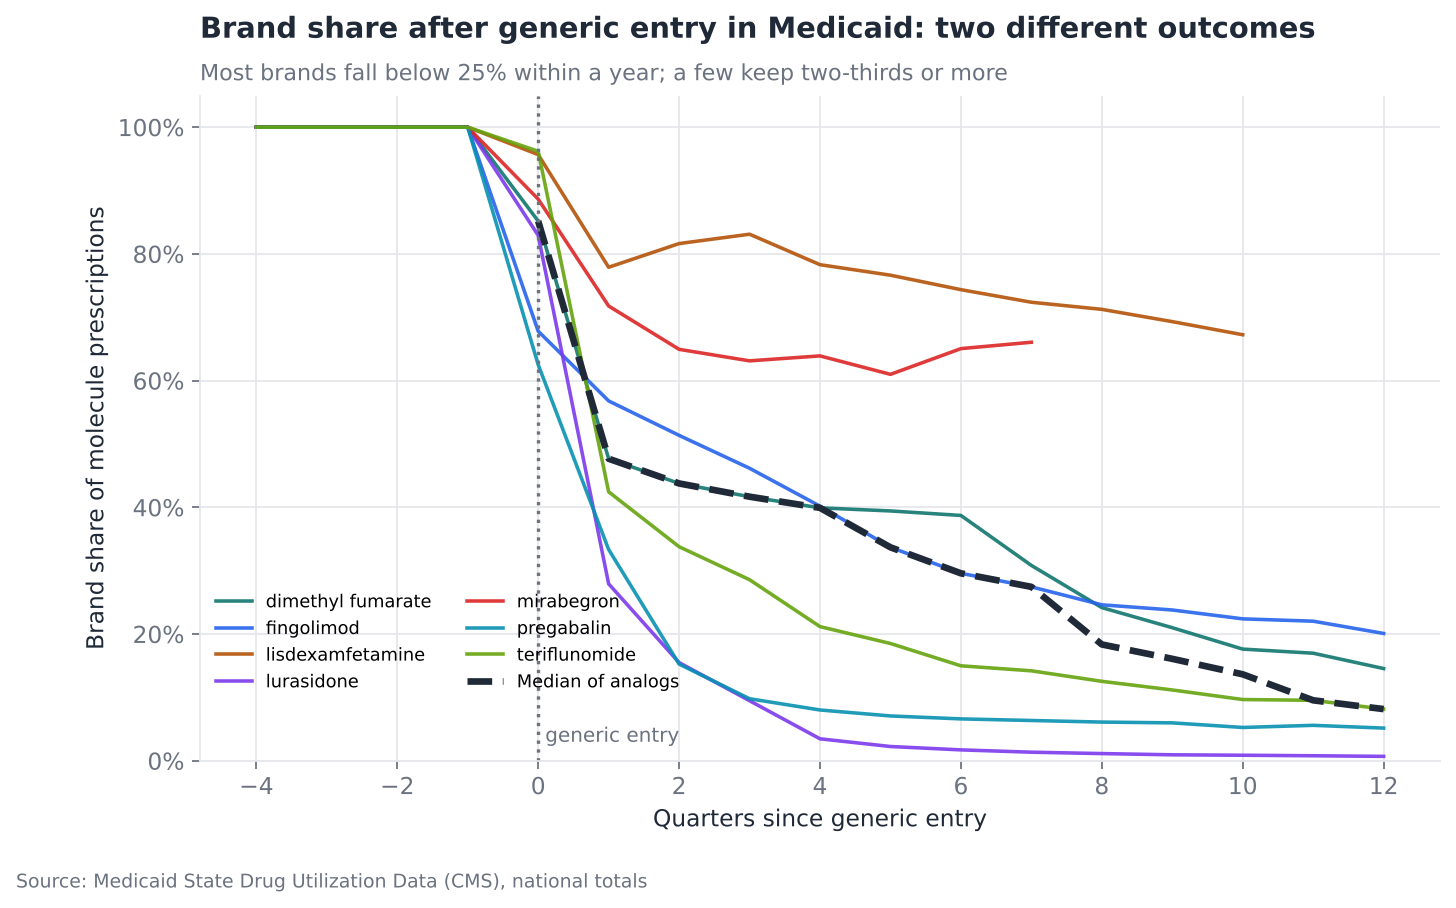

molecule,dimethyl fumarate,fingolimod,lisdexamfetamine,lurasidone,mirabegron,pregabalin,teriflunomide
t,,,,,,,
0.0,0.85,0.68,0.96,0.83,0.89,0.63,0.96
1.0,0.48,0.57,0.78,0.28,0.72,0.33,0.42
2.0,0.44,0.51,0.82,0.16,0.65,0.15,0.34
4.0,0.40,0.40,0.78,0.03,0.64,0.08,0.21
8.0,0.24,0.25,0.71,0.01,NaN,0.06,0.13


In [5]:
win = q[q["molecule"].isin(analogs) & q["t"].between(-4, 12)]
curve = win.pivot_table(index="t", columns="molecule", values="brand_share")

fig, ax = plt.subplots(figsize=(10, 5.4))
for i, m in enumerate(curve.columns):
    ax.plot(curve.index, curve[m], color=style.PALETTE[i % len(style.PALETTE)], lw=1.6, alpha=0.9, label=m)
med = curve.loc[curve.index >= 0].median(axis=1)
ax.plot(med.index, med.values, color=style.INK, lw=3, ls="--", label="Median of analogs")
ax.axvline(0, color=style.MUTED, ls=":")
ax.text(0.1, 0.03, "generic entry", color=style.MUTED, fontsize=9)
ax.set_xlabel("Quarters since generic entry")
ax.set_ylabel("Brand share of molecule prescriptions")
style.pct(ax)
ax.set_ylim(0, 1.05)
ax.set_title("Brand share after generic entry in Medicaid: two different outcomes")
style.subtitle(ax, "Most brands fall below 25% within a year; a few keep two-thirds or more")
ax.legend(fontsize=8, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 0.08))
style.source(fig, SRC)
style.save(fig, FIG / "01_erosion_curves.png")
curve.loc[[0, 1, 2, 4, 8]].round(2)

### Why do some brands keep their share?

In Medicaid, each state's **preferred drug list** (PDL) favours whichever
product is cheapest *after rebates*. Brands pay Medicaid large statutory and
supplemental rebates, so in the months after generic entry, while only a few
generics are on the market and their prices are still high, the brand can be
cheaper to the state than the generic. States then keep the brand preferred and
pharmacies keep dispensing it. Vyvanse (lisdexamfetamine) and Myrbetriq
(mirabegron) show this pattern. The ADHD stimulant shortage of 2023–24 also
limited generic Vyvanse supply.

This is why a Medicaid forecast needs two regimes, not one average curve.

### Fit one curve per analog

`share(t) = floor + (1 − floor) · e^(−k·(t + 0.5))` for t ≥ 0

- **k** sets the speed of erosion. Higher k means faster loss.
- **floor** is the share the brand keeps long-term.
- The `+ 0.5` reflects that generics launch partway through their entry
  quarter, so on average that quarter only has half a quarter of competition.

In [6]:
def erosion(t, k, floor):
    return floor + (1 - floor) * np.exp(-k * (np.asarray(t, dtype=float) + 0.5))


def fit(m):
    d = q[(q["molecule"] == m) & q["t"].between(0, 12)].dropna(subset=["brand_share"])
    (k, fl), _ = curve_fit(erosion, d["t"], d["brand_share"], p0=[1.0, 0.1], bounds=([0.01, 0.0], [10, 0.95]))
    at = lambda tt: float(d.loc[d["t"] == tt, "brand_share"].iloc[0]) if (d["t"] == tt).any() else np.nan
    return {"k": k, "floor": fl, "share_q1": at(1), "share_q4": at(4), "quarters": len(d)}


fits = pd.DataFrame({m: fit(m) for m in analogs}).T
fits["regime"] = np.where(fits["floor"] >= 0.5, "brand retained", "normal erosion")
fits = fits.sort_values("k")
fits.to_csv(TAB / "analog_fits.csv")
fits.round(3)

,k,floor,share_q1,share_q4,quarters,regime
lisdexamfetamine,0.366,0.701,0.779,0.783,11.0,brand retained
fingolimod,0.443,0.238,0.568,0.402,13.0,normal erosion
dimethyl fumarate,0.445,0.227,0.477,0.399,13.0,normal erosion
teriflunomide,0.494,0.103,0.424,0.212,13.0,normal erosion
lurasidone,0.706,0.004,0.279,0.035,13.0,normal erosion
pregabalin,0.902,0.060,0.333,0.080,13.0,normal erosion
mirabegron,0.941,0.632,0.718,0.639,8.0,brand retained


## 3. Back-test: could the analogs have predicted Brilinta and Entresto?

Both lost exclusivity in 2025 (Brilinta in Q2, Entresto in Q3) and neither was
used to fit the curves. The forecast uses the median k and floor of the
**normal-erosion** analogs, with the analog range as a band.

molecule
sacubitril/valsartan    0.060
ticagrelor              0.188
Name: error, dtype: float64


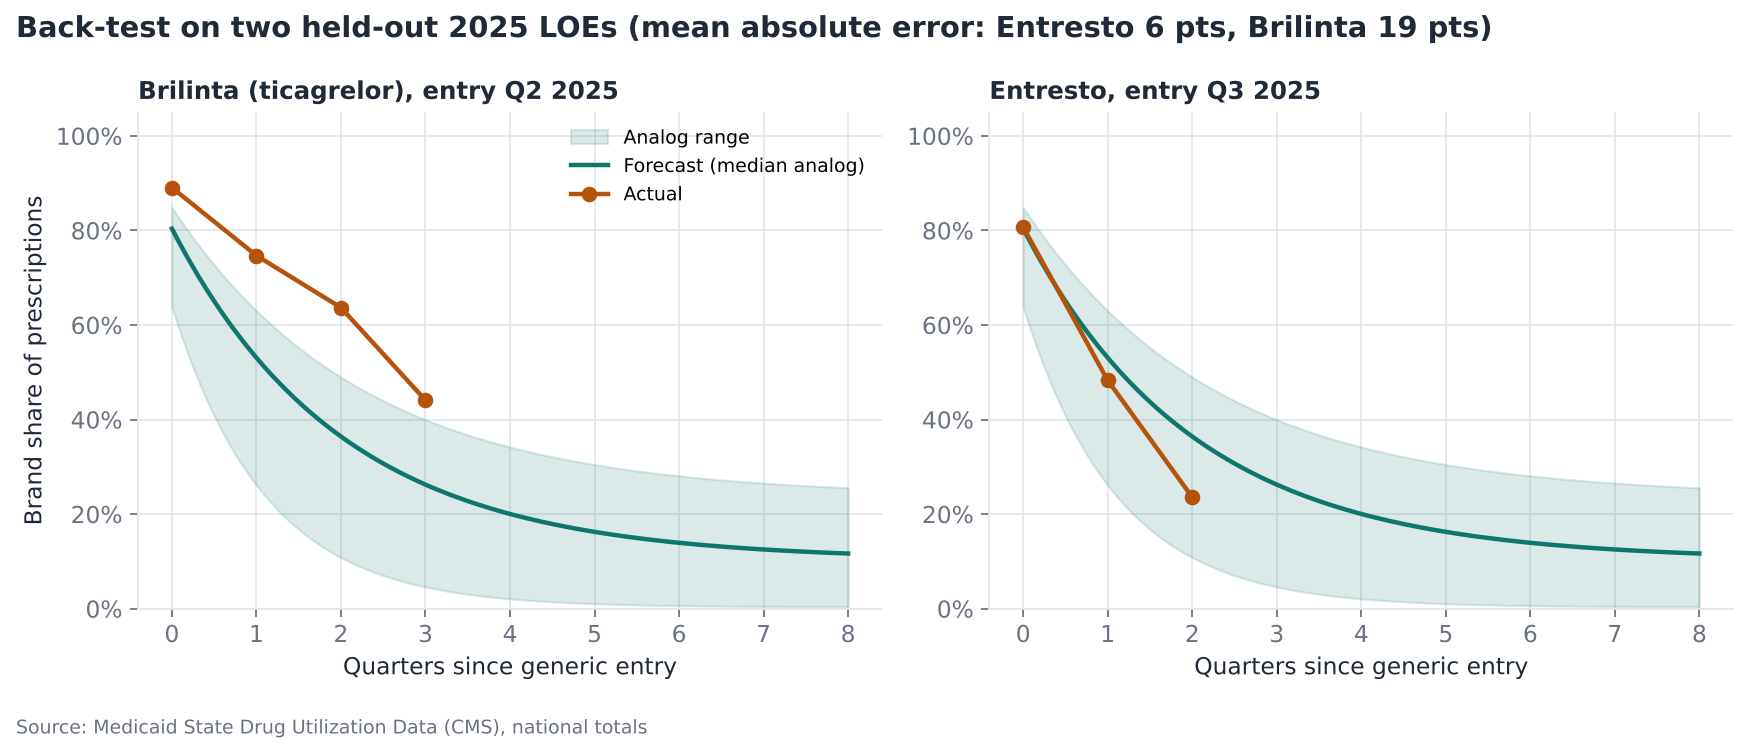

,molecule,period,t,brand_share,forecast,error
440,ticagrelor,2025Q2,0.0,0.891,0.804,-0.087
441,ticagrelor,2025Q3,1.0,0.747,0.531,-0.216
442,ticagrelor,2025Q4,2.0,0.637,0.364,-0.273
443,ticagrelor,2026Q1,3.0,0.441,0.263,-0.178
367,sacubitril/valsartan,2025Q3,0.0,0.807,0.804,-0.003
368,sacubitril/valsartan,2025Q4,1.0,0.483,0.531,0.048
369,sacubitril/valsartan,2026Q1,2.0,0.236,0.364,0.128


In [7]:
normal = fits[fits["regime"] == "normal erosion"]
retained = fits[fits["regime"] == "brand retained"]
K = {"median": normal["k"].median(), "slow": normal["k"].min(), "fast": normal["k"].max()}
F = {"median": normal["floor"].median(), "slow": normal["floor"].max(), "fast": normal["floor"].min()}

rows, fig_bt = [], plt.figure(figsize=(11, 4.4))
for i, m in enumerate(TESTS):
    act = q[(q["molecule"] == m) & (q["t"] >= 0)].sort_values("t")[["t", "period", "brand_share"]].copy()
    act["forecast"] = erosion(act["t"], K["median"], F["median"])
    act["molecule"] = m
    rows.append(act)
    ax = fig_bt.add_subplot(1, 2, i + 1)
    tt = np.linspace(0, 8, 100)
    ax.fill_between(tt, erosion(tt, K["fast"], F["fast"]), erosion(tt, K["slow"], F["slow"]),
                    color=style.ACCENT, alpha=0.15, label="Analog range")
    ax.plot(tt, erosion(tt, K["median"], F["median"]), color=style.ACCENT, lw=2, label="Forecast (median analog)")
    ax.plot(act["t"], act["brand_share"], "o-", color=style.ACCENT_2, lw=2, label="Actual")
    name = {"ticagrelor": "Brilinta (ticagrelor), entry Q2 2025", "sacubitril/valsartan": "Entresto, entry Q3 2025"}[m]
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Quarters since generic entry")
    style.pct(ax)
    ax.set_ylim(0, 1.05)
    if i == 0:
        ax.set_ylabel("Brand share of prescriptions")
        ax.legend(fontsize=8.5, loc="upper right")
bt = pd.concat(rows)
bt["error"] = bt["forecast"] - bt["brand_share"]
mae = bt["error"].abs().mean()
mae_by = bt.groupby("molecule")["error"].apply(lambda e: e.abs().mean())
print(mae_by.round(3))
fig_bt.suptitle(f"Back-test on two held-out 2025 LOEs (mean absolute error: Entresto "
               f"{mae_by['sacubitril/valsartan'] * 100:.0f} pts, Brilinta {mae_by['ticagrelor'] * 100:.0f} pts)",
                x=0.01, ha="left", fontsize=13, fontweight="bold", color=style.INK)
style.source(fig_bt, SRC)
fig_bt.tight_layout()
style.save(fig_bt, FIG / "02_backtest.png")
bt[["molecule", "period", "t", "brand_share", "forecast", "error"]].round({"brand_share": 3, "forecast": 3, "error": 3})

**Entresto** tracked the median forecast closely. **Brilinta** eroded more
slowly than any training analog. Six generic makers launched the 90 mg tablet
on day one, so the slower decline points to factors the public data cannot
show, such as state preferred-drug-list status and brand contracting.

The lesson for forecasting is that quarter-level errors of 10–20 share points
are normal even with good analogs. Plans should be built on a range, and the
early post-entry quarters should be watched closely to work out which regime a
brand is in.

## 4. Biologics erode far more slowly

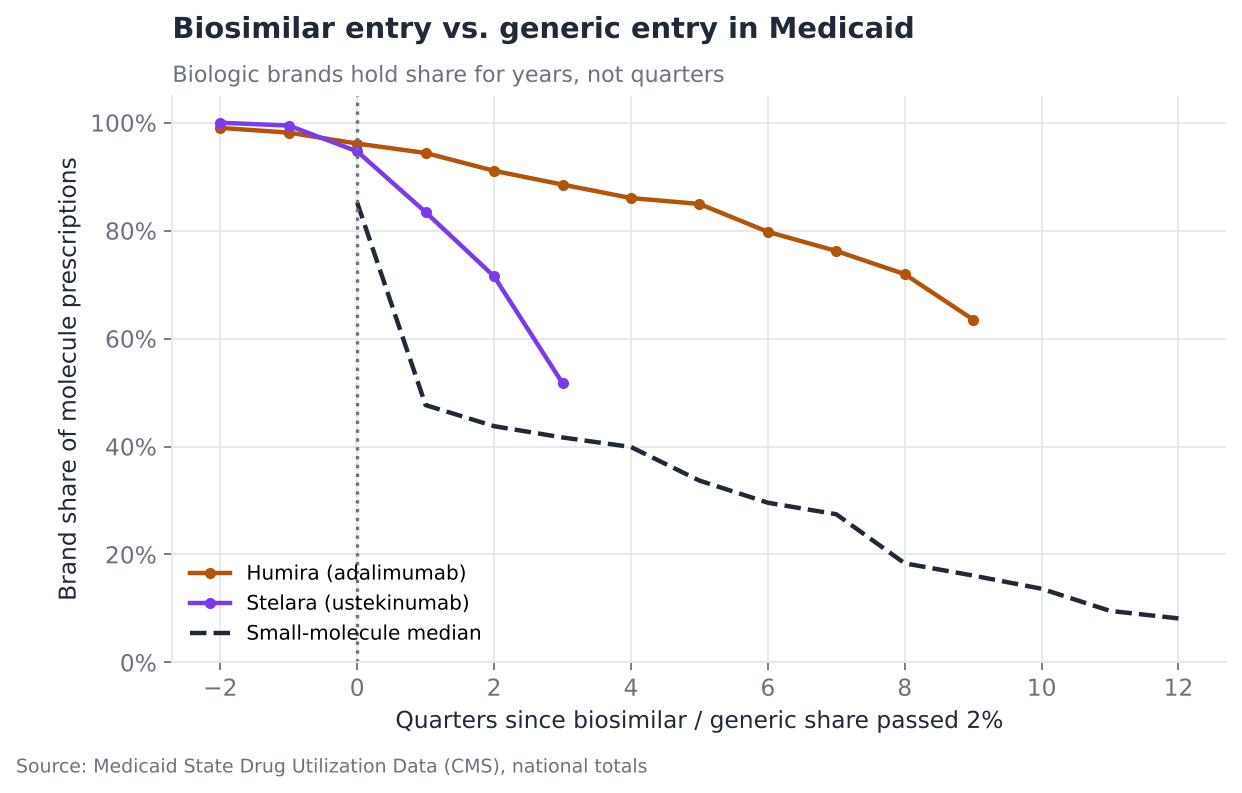

molecule,adalimumab,ustekinumab
t,,
0.0,0.96,0.95
2.0,0.91,0.72
4.0,0.86,NaN
6.0,0.80,NaN
8.0,0.72,NaN


In [8]:
bio = [m for m in BIOLOGICS if m in entries]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, m in enumerate(sorted(bio)):
    d = q[(q["molecule"] == m) & q["t"].between(-2, 12)]
    ax.plot(d["t"], d["brand_share"], "o-", color=[style.ACCENT_2, "#7C3AED"][i % 2], lw=2, ms=4,
            label={"adalimumab": "Humira (adalimumab)", "ustekinumab": "Stelara (ustekinumab)"}[m])
ax.plot(med.index, med.values, color=style.INK, lw=2, ls="--", label="Small-molecule median")
ax.axvline(0, color=style.MUTED, ls=":")
ax.set_xlabel("Quarters since biosimilar / generic share passed 2%")
ax.set_ylabel("Brand share of molecule prescriptions")
style.pct(ax)
ax.set_ylim(0, 1.05)
ax.set_title("Biosimilar entry vs. generic entry in Medicaid")
style.subtitle(ax, "Biologic brands hold share for years, not quarters")
ax.legend(fontsize=9, loc="lower left")
style.source(fig, SRC)
style.save(fig, FIG / "03_biologics_vs_small_molecules.png")
bio_tbl = q[q["molecule"].isin(bio) & q["t"].isin([0, 2, 4, 6, 8, 10])].pivot_table(index="t", columns="molecule", values="brand_share")
bio_tbl.round(2)

## 5. Eliquis in Medicaid: a forecast with a twist

Generic apixaban is expected from **April 1, 2028**, after Bristol Myers Squibb
and Pfizer won their patent case. A standard analog forecast would show brand
prescriptions collapsing within a year.

But on December 19, 2025, BMS agreed with the US government to supply Eliquis
to **Medicaid free of charge from January 1, 2026**. The data already show the
effect: Medicaid's reimbursement per Eliquis prescription fell sharply in
Q1 2026 while prescription volume barely moved. If the brand is free to states,
no generic can undercut it on net cost, and state PDLs have every reason to keep
Eliquis preferred. That is the **brand-retained** regime seen with Vyvanse and
Myrbetriq, only stronger.

So the forecast shows brand **prescriptions** (not dollars, which no longer
measure manufacturer revenue in Medicaid) under both regimes.

period  brand_rx   brand_usd  usd_per_rx
2024Q4  520391.0 329401269.0       633.0
2025Q1  528517.0 341910836.0       647.0
2025Q2  540095.0 348378374.0       645.0
2025Q3  563249.0 367702356.0       653.0
2025Q4  556404.0 363295090.0       653.0
2026Q1  521685.0 219824833.0       421.0


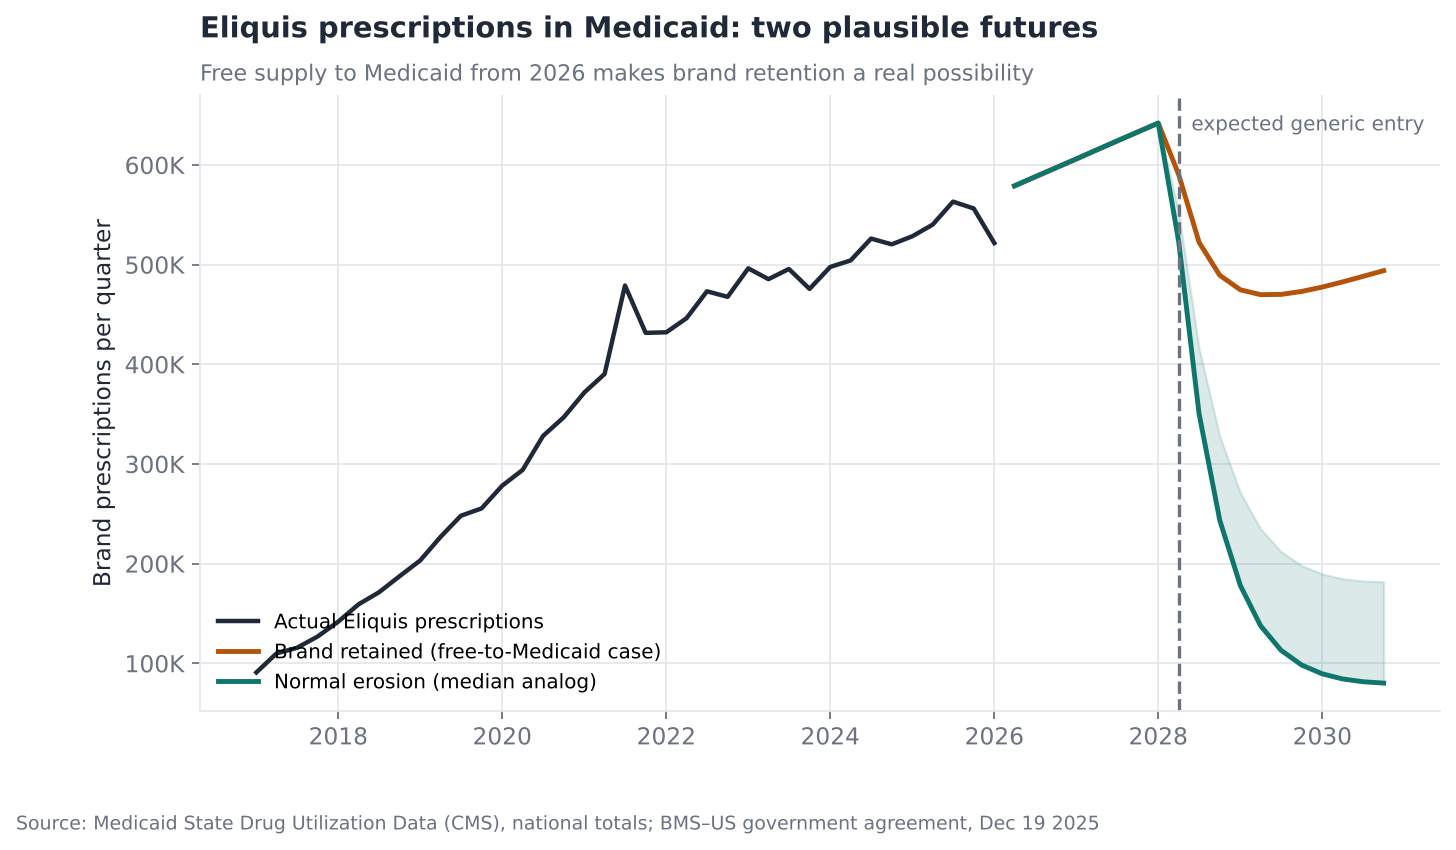

,molecule_rx,Normal erosion (median),Normal erosion (slow),Brand retained
period,,,,
2026,2.29,2.29,2.29,2.29
2027,2.48,2.48,2.48,2.48
2028,2.62,1.76,1.94,2.24
2029,2.77,0.53,0.92,1.89
2030,2.91,0.34,0.74,1.94


In [9]:
ELQ = "apixaban"
e = q[q["molecule"] == ELQ].sort_values("period").copy()
e["usd_per_rx"] = e["brand_usd"] / e["brand_rx"]
print(e[["period", "brand_rx", "brand_usd", "usd_per_rx"]].tail(6).assign(period=lambda x: x["period"].astype(str)).round(0).to_string(index=False))

hist = e[e["period"] < latest].tail(8)            # latest quarter excluded from the trend: claims still arriving
slope, intercept = np.polyfit(range(len(hist)), hist["brand_rx"], 1)
entry = pd.Period("2028Q2", freq="Q")
fut = pd.period_range(latest + 1, pd.Period("2030Q4", freq="Q"), freq="Q")
fc = pd.DataFrame({"period": fut})
fc["molecule_rx"] = [intercept + slope * (len(hist) + (p - hist["period"].iloc[-1]).n - 1) for p in fut]
t = np.array([(p - entry).n for p in fut])
scen = {
    "Normal erosion (median)": (K["median"], F["median"]),
    "Normal erosion (slow)": (K["slow"], F["slow"]),
    "Brand retained": (retained["k"].median(), retained["floor"].median()),
}
for name, (k, fl) in scen.items():
    fc[name] = fc["molecule_rx"] * np.where(t < 0, 1.0, erosion(np.clip(t, 0, None), k, fl))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(e["period"].dt.to_timestamp(), e["brand_rx"], color=style.INK, lw=2, label="Actual Eliquis prescriptions")
x = fc["period"].dt.to_timestamp()
ax.plot(x, fc["Brand retained"], color=style.ACCENT_2, lw=2.2, label="Brand retained (free-to-Medicaid case)")
ax.plot(x, fc["Normal erosion (median)"], color=style.ACCENT, lw=2.2, label="Normal erosion (median analog)")
ax.fill_between(x, fc["Normal erosion (median)"], fc["Normal erosion (slow)"], color=style.ACCENT, alpha=0.15)
ax.axvline(entry.to_timestamp(), color=style.MUTED, ls="--")
ax.text(entry.to_timestamp(), ax.get_ylim()[1] * 0.97, "  expected generic entry", color=style.MUTED, fontsize=9, va="top")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K"))
ax.set_ylabel("Brand prescriptions per quarter")
ax.set_title("Eliquis prescriptions in Medicaid: two plausible futures")
style.subtitle(ax, "Free supply to Medicaid from 2026 makes brand retention a real possibility")
ax.legend(loc="lower left", fontsize=9)
style.source(fig, SRC + "; BMS–US government agreement, Dec 19 2025")
style.save(fig, FIG / "04_eliquis_scenarios.png")

annual = fc.groupby(fc["period"].dt.year)[["molecule_rx"] + list(scen)].sum()
annual.loc[latest.year] += e.loc[e["period"].dt.year == latest.year, "brand_rx"].sum()
(annual / 1e6).round(2)

What this means for each party:

- **Generic apixaban makers:** Medicaid is roughly 2 million prescriptions a
  year, but it may not be winnable in 2028 if free brand supply continues.
  Volume plans should treat Medicaid as upside, not base case.
- **BMS / Pfizer:** Medicaid is now a non-revenue channel for Eliquis, so the
  2028 revenue cliff will come from commercial and Medicare. Medicare already
  pays the negotiated price from 2026.
- **State Medicaid programmes:** Watch whether the free-supply terms run past
  2028. If they do, keeping Eliquis preferred is the cheapest option.

## 6. Machine learning extension: a state-level early-warning model

The national curves hide large differences between states, because each
state's Medicaid programme makes its own preferred-drug-list decisions. A
brand team, or a generic company planning supply, would like to know **within
two quarters of generic entry** where the brand will hold up and where it
will collapse.

**Set-up:**
- One row per **molecule × state**, using state-level SDUD data.
- **Features known after two quarters:** the state's brand share in the entry
  quarter (t=0) and the next (t=1), the drop between them, the national brand
  share in those same quarters, the size of the state's pre-entry brand market,
  and the state's track record (its average one-year brand share on *other*
  molecules).
- **Target:** the state's brand share one year after entry (t=4).
- **Validation:** *leave-one-molecule-out*. The model is trained on six analog
  molecules and tested on the seventh, rotating through all seven. Every
  prediction is for a molecule the model has never seen, as it would be in practice.
- **Extra test on 2025 LOEs:** the same approach with shorter horizons, because
  less time has passed. Brilinta at t=3 and Entresto at t=2.

**Models:** gradient-boosted trees and ridge regression (a linear model with a
penalty that keeps weights small). **Baselines:** (1) the national analog
median curve, the approach in section 3, and (2) "persistence", which assumes
the share stays where it was at t=1.

**Term:** *MAE* (mean absolute error) is the average gap between predicted
and actual brand share, in share points.

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

st = sd[(sd["state"] != "XX")].copy()
st[["molecule", "role"]] = st["product_name"].apply(lambda n: pd.Series(tag(n)))
st = st.dropna(subset=["molecule"])
st["period"] = pd.PeriodIndex.from_fields(year=st["year"], quarter=st["quarter"], freq="Q")
sq = (st.groupby(["molecule", "state", "period", "role"])["number_of_prescriptions"].sum()
        .unstack("role", fill_value=0).reset_index())
sq["share"] = sq["brand"] / (sq["brand"] + sq["competitor"]).replace(0, np.nan)
sq["t"] = [(p - entries[m]).n if m in entries else np.nan for m, p in zip(sq["molecule"], sq["period"])]
nat_share = q.dropna(subset=["t"]).drop_duplicates(["molecule", "t"]).set_index(["molecule", "t"])["brand_share"]


def state_rows(mols, horizon):
    out = []
    for m in mols:
        d = sq[sq["molecule"] == m]
        piv = d.pivot_table(index="state", columns="t", values="share")
        pre = d[d["t"].between(-4, -1)].groupby("state")["brand"].mean()
        need = [0, 1, horizon]
        if not all(t in piv.columns for t in need):
            continue
        r = pd.DataFrame({"share_t0": piv[0], "share_t1": piv[1], "target": piv[horizon], "pre_brand_rx": pre}).dropna()
        r = r[r["pre_brand_rx"] >= 300]                      # skip tiny state markets (suppression noise)
        r["drop_t0_t1"] = r["share_t0"] - r["share_t1"]
        r["nat_t0"], r["nat_t1"] = float(nat_share.loc[(m, 0.0)]), float(nat_share.loc[(m, 1.0)])
        r["log_pre_rx"] = np.log(r["pre_brand_rx"])
        r["molecule"] = m
        out.append(r.reset_index())
    return pd.concat(out, ignore_index=True)


def add_track_record(train_df, test_df):
    """State's average target share on the training molecules only (no leakage)."""
    rec = train_df.groupby("state")["target"].mean()
    for df in (train_df, test_df):
        df["state_record"] = df["state"].map(rec).fillna(rec.mean())
    return train_df, test_df


FEATS = ["share_t0", "share_t1", "drop_t0_t1", "nat_t0", "nat_t1", "log_pre_rx", "state_record"]
make = {"Gradient boosting": lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=3,
                                                                    min_samples_leaf=15, random_state=7),
        "Ridge regression": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0))}


def evaluate(train_mols, test_mols, horizon):
    rows = state_rows(train_mols + test_mols, horizon)
    tr, te = rows[rows["molecule"].isin(train_mols)].copy(), rows[rows["molecule"].isin(test_mols)].copy()
    tr, te = add_track_record(tr, te)
    for name, f in make.items():
        te[name] = np.clip(f().fit(tr[FEATS], tr["target"]).predict(te[FEATS]), 0, 1)
    # Baseline 1: national analog median curve (section 3), the same value for every state
    te["National analog curve"] = erosion(horizon, K["median"], F["median"])
    # Baseline 2: persistence
    te["Persistence (share at t=1)"] = te["share_t1"]
    return te


METHODS = ["Gradient boosting", "Ridge regression", "National analog curve", "Persistence (share at t=1)"]
lomo = pd.concat([evaluate([m for m in analogs if m != hold], [hold], 4) for hold in analogs], ignore_index=True)
mae_lomo = {k: (lomo[k] - lomo["target"]).abs().mean() for k in METHODS}
print(f"Leave-one-molecule-out: {len(lomo)} molecule-state rows across {lomo['molecule'].nunique()} molecules")
pd.Series(mae_lomo, name="MAE, share at t=4").round(3)

Leave-one-molecule-out: 200 molecule-state rows across 7 molecules


Gradient boosting             0.175
Ridge regression              0.175
National analog curve         0.330
Persistence (share at t=1)    0.175
Name: MAE, share at t=4, dtype: float64

In [11]:
recent = pd.concat([evaluate(analogs, ["ticagrelor"], 3), evaluate(analogs, ["sacubitril/valsartan"], 2)], ignore_index=True)
mae_recent = recent.groupby("molecule").apply(lambda g: pd.Series({k: (g[k] - g["target"]).abs().mean() for k in METHODS}),
                                              include_groups=False)
mae_recent.index = mae_recent.index.map({"ticagrelor": "Brilinta (t=3)", "sacubitril/valsartan": "Entresto (t=2)"})
mae_table = pd.concat([pd.DataFrame(mae_lomo, index=["Analogs, leave-one-out (t=4)"]), mae_recent])
mae_table.round(3)

,Gradient boosting,Ridge regression,National analog curve,Persistence (share at t=1)
"Analogs, leave-one-out (t=4)",0.175,0.175,0.330,0.175
Entresto (t=2),0.239,0.222,0.312,0.243
Brilinta (t=3),0.275,0.345,0.327,0.268


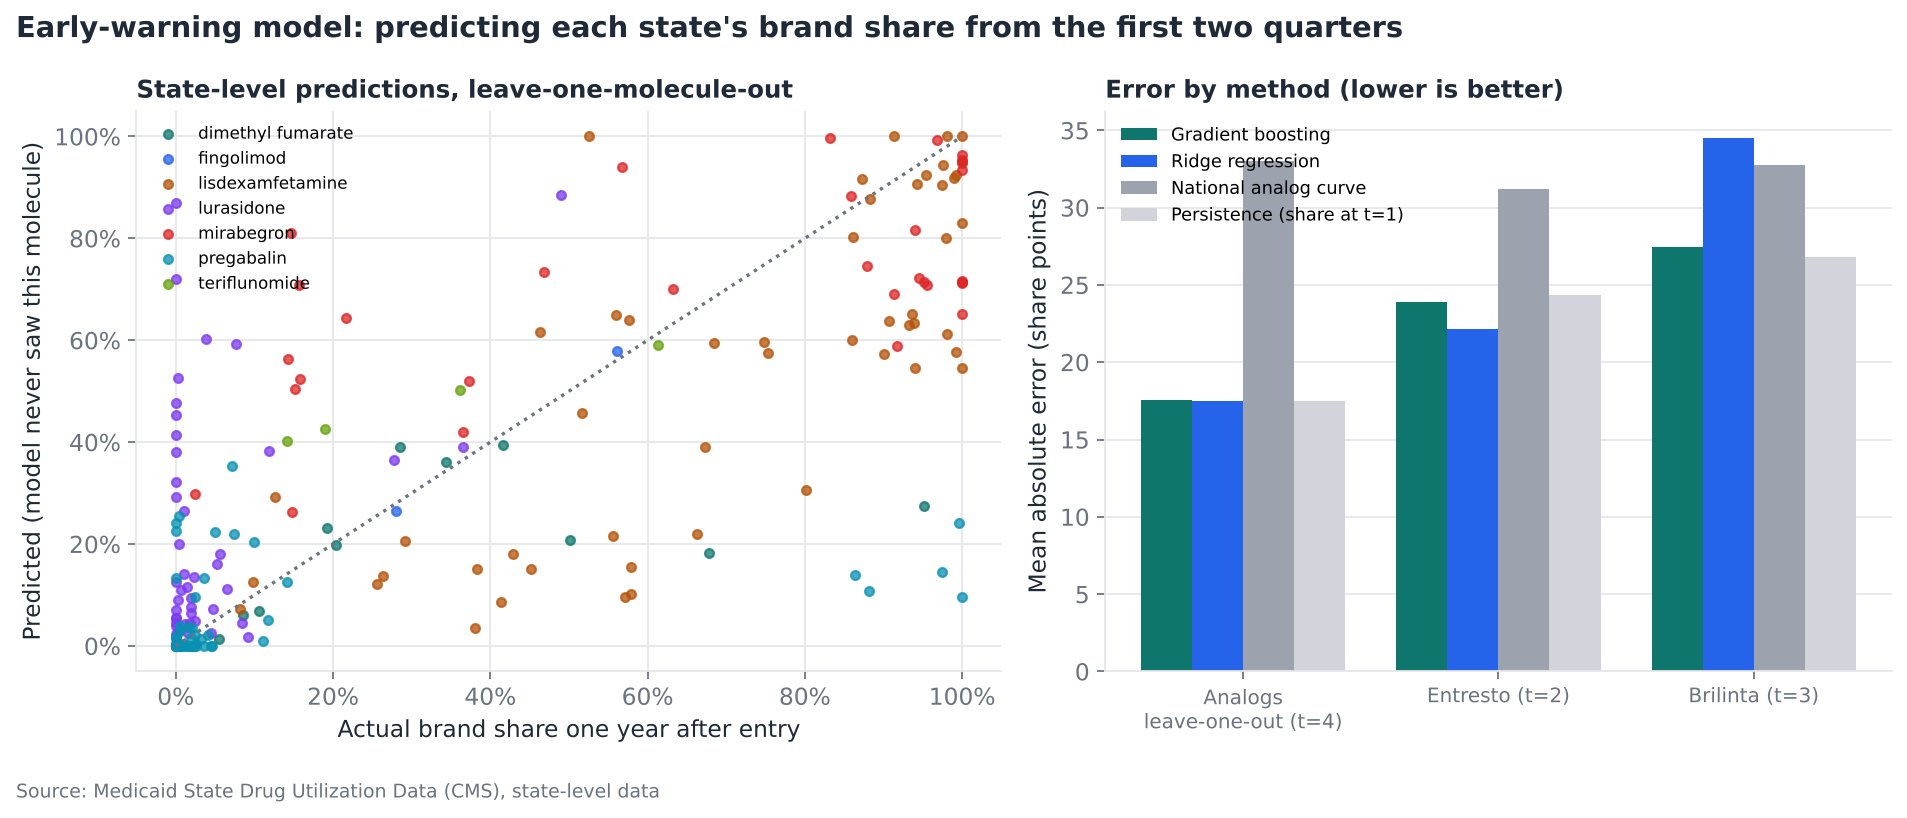

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
mols = sorted(lomo["molecule"].unique())
for i, m in enumerate(mols):
    d = lomo[lomo["molecule"] == m]
    ax.scatter(d["target"], d["Gradient boosting"], s=16, alpha=0.75, color=style.PALETTE[i % len(style.PALETTE)], label=m)
ax.plot([0, 1], [0, 1], color=style.MUTED, ls=":")
style.pct(ax, "x"); style.pct(ax, "y")
ax.set_xlabel("Actual brand share one year after entry")
ax.set_ylabel("Predicted (model never saw this molecule)")
ax.set_title("State-level predictions, leave-one-molecule-out", fontsize=11)
ax.legend(fontsize=7.5, loc="upper left")

ax = axes[1]
plot = mae_table.T * 100
xpos = np.arange(len(plot.columns))
w = 0.2
for i, (meth, c) in enumerate(zip(METHODS, [style.ACCENT, "#2563EB", style.NEUTRAL, "#D1D5DB"])):
    ax.bar(xpos + (i - 1.5) * w, plot.loc[meth], width=w, color=c, label=meth)
ax.set_xticks(xpos)
ax.set_xticklabels([c.replace(", leave-one-out", "\nleave-one-out") for c in plot.columns], fontsize=9)
ax.set_ylabel("Mean absolute error (share points)")
ax.set_title("Error by method (lower is better)", fontsize=11)
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
fig.suptitle("Early-warning model: predicting each state's brand share from the first two quarters",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=style.INK)
style.source(fig, SRC.replace("national totals", "state-level data"))
fig.tight_layout()
style.save(fig, FIG / "05_ml_state_early_warning.png")

**Reading the result honestly:**
- Moving from one national curve to **state-level early data roughly halves
  the error** (about 17–24 share points against 31–33).
- The machine-learning models do **not** beat the simple persistence rule
  ("the share stays where it was at t=1") by a meaningful margin. With only
  seven analog molecules, the state's own early share already carries most of
  the signal, and there is not enough variety for a model to learn more.
- The practical recommendation is therefore the simple one: watch each state's
  first two quarters and use persistence as the base forecast. Keep the model
  pipeline ready to retrain as more LOEs, such as Brilinta and Entresto, mature
  into training data, because that is when extra features (state track record,
  market size) can start to add value.

**How to use it:** two quarters after generic entry, score every state. Those
predicted to keep the brand preferred are where brand contracting effort and
supply should go (for the brand) or where launch volumes will lag (for a
generic). For Eliquis in 2028 the same model can run as soon as the first two
quarters of state data are published, about six months after entry.

## 7. Summary numbers used in the README

In [13]:
q1 = q[q["molecule"].isin(analogs) & (q["t"] == 1)]["brand_share"]
q4 = q[q["molecule"].isin(analogs) & (q["t"] == 4)]["brand_share"]
q4n = q[q["molecule"].isin(normal.index) & (q["t"] == 4)]["brand_share"]
summary = {
    "latest_quarter": str(latest),
    "training_analogs": analogs, "excluded": EXCLUDE, "tests": TESTS,
    "median_brand_share_q1": float(q1.median()), "median_brand_share_q4": float(q4.median()),
    "normal_regime_q4_median": float(q4n.median()),
    "normal_regime": list(normal.index), "retained_regime": list(retained.index),
    "backtest_mae": float(mae), "backtest_mae_by_molecule": {k: float(v) for k, v in mae_by.items()},
    "backtest_detail": bt[["molecule", "t", "brand_share", "forecast"]].round(3).to_dict("records"),
    "eliquis_usd_per_rx_2025q4": float(e.loc[e["period"] == pd.Period("2025Q4", freq="Q"), "usd_per_rx"].iloc[0]),
    "eliquis_usd_per_rx_latest": float(e["usd_per_rx"].iloc[-1]),
    "eliquis_rx_2025": float(e.loc[e["period"].dt.year == 2025, "brand_rx"].sum()),
    "eliquis_2029_rx": {k: float(annual.loc[2029, k]) for k in scen},
    "biologic_share_q2": {m: float(bio_tbl.loc[2, m]) for m in bio_tbl.columns},
    "humira_share_q8": float(bio_tbl.loc[8, "adalimumab"]) if 8 in bio_tbl.index else None,
    "entries": {m: str(p) for m, p in entries.items()},
    "ml_lomo_rows": int(len(lomo)), "ml_mae": mae_table.round(4).to_dict(orient="index"),
}
(TAB / "summary.json").write_text(json.dumps(summary, indent=1, default=str))
fc.assign(period=fc["period"].astype(str)).round(0).to_csv(TAB / "eliquis_forecast_quarterly.csv", index=False)
summary

{'latest_quarter': '2026Q1',
 'training_analogs': ['dimethyl fumarate',
  'fingolimod',
  'lisdexamfetamine',
  'lurasidone',
  'mirabegron',
  'pregabalin',
  'teriflunomide'],
 'excluded': {'varenicline': 'brand withdrawn (2021 recall), not a normal LOE',
  'rivaroxaban': 'partial generic entry, one quarter of data'},
 'tests': ['ticagrelor', 'sacubitril/valsartan'],
 'median_brand_share_q1': 0.4767255216693419,
 'median_brand_share_q4': 0.39917154980804204,
 'normal_regime_q4_median': 0.21176470588235294,
 'normal_regime': ['fingolimod',
  'dimethyl fumarate',
  'teriflunomide',
  'lurasidone',
  'pregabalin'],
 'retained_regime': ['lisdexamfetamine', 'mirabegron'],
 'backtest_mae': 0.13331631743500102,
 'backtest_mae_by_molecule': {'sacubitril/valsartan': 0.059820268396915045,
  'ticagrelor': 0.18843835421356553},
 'backtest_detail': [{'molecule': 'ticagrelor',
   't': 0.0,
   'brand_share': 0.891,
   'forecast': 0.804},
  {'molecule': 'ticagrelor',
   't': 1.0,
   'brand_share': 0